1) Create conda or venv environment on head node <br>
2) Activate environment <br>
3) Install required packages (scanpy) + jupyterlab <br>
4) Submit interactive job from head node: <br>
    ```bsub -G team361 -q teramem -n4 -M 400000 -R"select[mem>400000 ] rusage[mem=400000 ]" -Is /bin/bash``` <br>
5) Activate environment <br>
6) Run  <br>
    ```jupyter-lab --no-browser --ip=0.0.0.0 --port=8888 &``` <br>
7) Forward port on local machine: <br>
    ```ssh -o TCPKeepAlive=no -o ServerAliveInterval=15 -L 8882:b11-hm-01:8888 sb75@farm22-head1.internal.sanger.ac.uk``` <br>
8) Open browser and go to ```http://localhost:8882/```

In [1]:
import scanpy as sc
print(sc.__version__)

1.11.0


In [2]:
artifacts_folder_path = '../../artifacts'
silver_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS/silver'

load_timestamp = '06032025_085433_744' # model load timestamp
read_checkpoint = 'ep2' # model read checkpoint

In [3]:
adata = sc.read_h5ad(f'{artifacts_folder_path}/hst_corpus_70m/{load_timestamp}/adata_{read_checkpoint}_1000-1007-1008_combined.h5ad')

In [4]:
adata # 11,036,633 cells

AnnData object with n_obs × n_vars = 11036633 × 0
    obs: 'tissue', 'gene_panel_size', 'dataset', 'batch', 'cell', 'dataset_batch'
    obsm: 'cell_emb_layer_6', 'neighborhood_emb_layer_6', 'spatial'

In [15]:
adata.obs.tail(1)

,tissue,gene_panel_size,dataset,batch,cell,dataset_batch
cell_id,,,,,,
1008_batch3_339873,embryo,4949,1008,batch3,339873,1008batch3


In [6]:
# Cell embedding 
adata.obsm['cell_emb_layer_6']

array([[-0.19866796, -1.1689146 ,  0.6968614 , ..., -0.23176877,
        -0.4604415 , -0.8098403 ],
       [-0.02528332, -1.2360452 ,  0.8722799 , ..., -0.4289632 ,
        -0.4669282 , -0.84774184],
       [ 0.02260344, -1.0566895 ,  0.72681105, ..., -0.31961825,
        -0.40863675, -0.6516125 ],
       ...,
       [ 0.03400472, -0.11369315, -0.5179839 , ..., -0.37730408,
        -0.6298088 ,  1.087131  ],
       [ 0.18488342, -0.30891493,  0.6592114 , ...,  0.15744121,
        -0.5670184 ,  0.2699851 ],
       [-0.11079998, -0.16196644,  0.00575836, ...,  0.96375215,
        -0.32320967,  0.14491397]], dtype=float32)

In [7]:
# Neighborhood embedding
adata.obsm['neighborhood_emb_layer_6']

array([[-0.089791  , -1.1209575 ,  0.6548873 , ..., -0.21554403,
        -0.45764506, -0.6973041 ],
       [-0.10830826, -1.043863  ,  0.7235621 , ..., -0.40349972,
        -0.45846432, -0.83936155],
       [-0.04385012, -1.1190381 ,  0.73053443, ..., -0.3944042 ,
        -0.42328876, -0.80586547],
       ...,
       [-0.18849733,  0.0128791 , -0.54678404, ..., -0.42648792,
        -0.5907013 ,  0.99991834],
       [ 0.04217475, -0.4288522 ,  0.79689425, ...,  0.1758452 ,
        -0.34123358,  0.29345286],
       [ 0.24796833, -0.42090374,  0.32634595, ...,  0.77065617,
        -0.7654977 ,  0.01327429]], dtype=float32)

In [8]:
adata.obs[['dataset', 'batch', 'cell']] = [s.split('_') for s in adata.obs.index]
adata.obs['dataset_batch'] = adata.obs['dataset'].astype(str) + adata.obs['batch'].astype(str)
adata.obs['cell'] = adata.obs['cell'].astype(int)

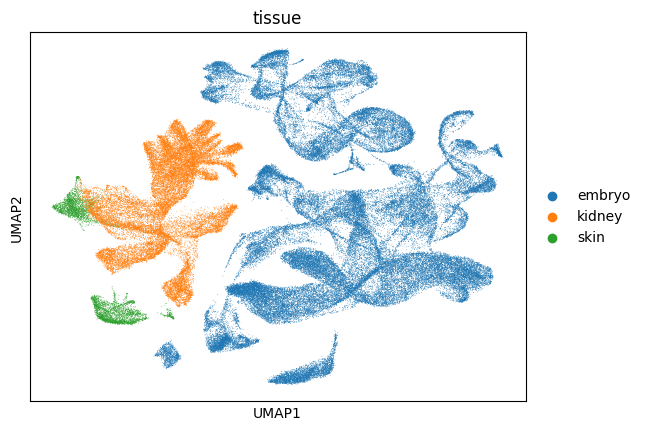

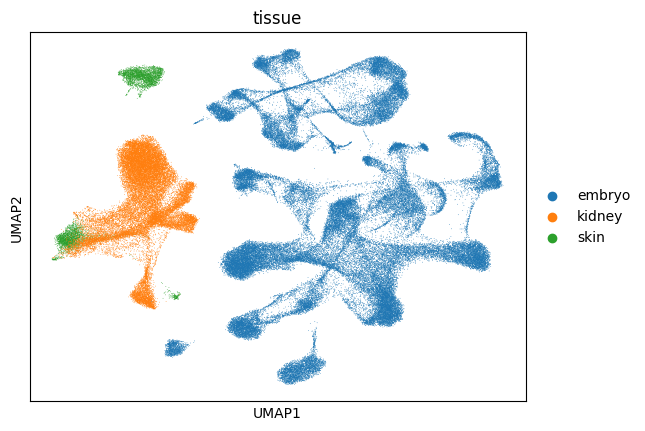

In [10]:
# Perform stratified subsampling based on batch
sample_frac = 0.01 # 1 percent subsample
random_state = 42
sampled_df = adata.obs.groupby(['dataset', 'batch'], group_keys=False).apply(
        lambda x: x.sample(frac=sample_frac, replace=False, random_state=random_state))
adata_subset = adata[sampled_df.index]
del(sampled_df)

label = 'tissue'
# Neighborhood embedding UMAP
sc.pp.neighbors(adata_subset,
                n_neighbors=15,
                use_rep='neighborhood_emb_layer_6',
                key_added='neighborhood')
sc.tl.umap(adata_subset,
           neighbors_key='neighborhood',
           key_added='neighborhood_umap')
adata_subset.obsm['X_umap'] = adata_subset.obsm['neighborhood_umap']
sc.pl.umap(adata_subset,
           neighbors_key='neighborhood',
           color=label)

# Cell embedding UMAP
sc.pp.neighbors(adata_subset,
                n_neighbors=15,
                use_rep='cell_emb_layer_6',
                key_added='cell')
sc.tl.umap(adata_subset,
           neighbors_key='cell',
           key_added='cell_umap')
adata_subset.obsm['X_umap'] = adata_subset.obsm['cell_umap']
sc.pl.umap(adata_subset,
           neighbors_key='cell',
           color=label)

In [ ]:
# Dataset ID 1000: eczema Lloyd
# Dataset ID 1007: kidney Daniyal
# Dataset ID 1008: embryo Adam

# Kidney raw data
# xhk1007-CV1-41b_1p
# xhk1007-CV2-41b_1p
# xhk1007-CV3-41b_1p
# xhk1007-CV4-41b_1p
# xhk1007-CV5-41b_1p
# xhk1007-CV6-41b_1p
# xhk1007-CV7-41b_1p
# xhk1007-CV8-41b_1p
# xhk1007-CV9-41b_1p

adata_raw = sc.read_h5ad(f'{silver_folder_path}/xhk1007-CV1-41b_1p/CV1-KID-0-FO-1.h5ad')

In [ ]:
# `original_cell_id` column

#'sample_batch_map': {
#    'CV1-KID-0-FO-1': 36,
#    'CV1-KID-0-FT-1': 14,
#    'CV1-KID-0-FT-2': 20,
#    'CV1-KID-0-FT-3': 1,
#    'CV2-KID-0-FO-1': 17,
#    'CV2-KID-0-FO-2': 33,
#    'CV2-KID-0-FT-1-s2': 4,
#    'CV2-KID-0-FT-2': 2,
#    'CV3-KID-0-FT-1-s3': 21,
#    'CV3-KID-0-FT-2-s3': 28,
#    'CV3-KID-0-FT-3-s3': 35,
#    'CV3-KID-0-FT-4-s3': 8,
#    'CV3-KID-0-FT-5': 16,
#    'CV4-KID-0-FO-1': 37,
#    'CV4-KID-0-FT-1-s3': 9,
#    'CV4-KID-0-FT-2-s3': 23,
#    'CV4-KID-0-FT-3-S3': 40,
#    'CV4-KID-0-FT-4-S3': 10,
#    'CV5-KID-0-FO-1': 31,
#    'CV5-KID-0-FT-1-s3': 38,
#    'CV5-KID-0-FT-2-s3': 5,
#    'CV5-KID-0-FT-4-S3': 7,
#    'CV6-KID-0-FO-1': 0,
#    'CV6-KID-0-FT-1': 27,
#    'CV6-KID-0-FT-2-s3': 3,
#    'CV6-KID-0-FT-3-s3': 12,
#    'CV6-KID-0-FT-4-S3': 19,
#    'CV6-KID-0-FT-5-S3': 24,
#    'CV7-KID-0-FO-1': 26,
#    'CV7-KID-0-FT-1-s3': 29,
#    'CV7-KID-0-FT-2-s3': 32,
#    'CV7-KID-0-FT-3-S3': 15,
#    'CV7-KID-0-FT-4-S3': 13,
#    'CV8-KID-0-FO-1': 18,
#    'CV8-KID-0-FT-1-s3': 11,
#    'CV9-KID-0-FO-1': 6,
#    'CV9-KID-0-FT-1-s3': 25,
#    'CV9-KID-0-FT-2-S3': 34,
#    'CV9-KID-0-FT-3-S3': 30,
#    'CV9-KID-0-FT-4-S3': 39,
#    'CV9-KID-0-FT-5-S4': 22}

In [ ]:
adata_raw.obs.head(1)